# Лабораторная работа № 5
## Решение задачи многомерной регрессии
**Цель работы**: изучение принципов решения задачи многомерной регрессии с использованием методов машинного обучения.

Проанализируем датасет Ecommerce_Customers. Набор данных содержит сведения о клиентах компании электронной коммерции, которая продает одежду онлайн, а также проводит консультации по стилю и одежде в магазине.

**Признаки**:
* Email – электронная почта
* Address – адрес
* Avatar – аватар
* Avg Session Length – средняя продолжительность сеанса консультирования по стилю в магазине для аватара
* Time on App – среднее время, проведенное в приложении в минутах
* Time on Website – среднее время, проведенное на веб-сайте в минутах
* Length of Membership – продолжительность членства (сколько лет клиент является участником)
* Yearly Amount Spent – годовая сумма расходов

### 0. Импорт необходимых библиотек и загрузка датасета

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from IPython.display import display

df = pd.read_csv('Ecommerce_Customers.csv', skipinitialspace=True)
df.head()

,Email,Address,Avatar,Avg Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank TunnelWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer CommonDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582Cobbborough, DC ...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David ThroughwayPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez PassagePort Jacobville, PR 372...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


In [2]:
print("Размер:", df.shape)

Размер: (500, 8)


### 1. Анализ целевой переменной

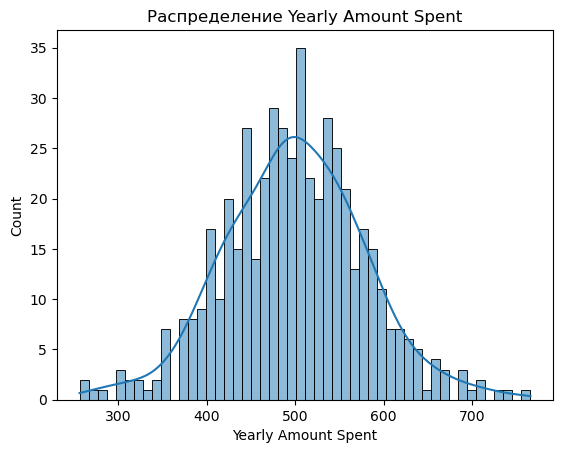

In [3]:
sns.histplot(df['Yearly Amount Spent'], bins=50, kde=True)
plt.title('Распределение Yearly Amount Spent')
plt.show()

В датасете отсутствуют какие-либо условия нормализации, поэтому преобразования пропущены

### 2. Информация о датасете 

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg Session Length    500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


### 3. Проверка на наличие пропущенных значений

In [5]:
print(df.isnull().sum())

Email                   0
Address                 0
Avatar                  0
Avg Session Length      0
Time on App             0
Time on Website         0
Length of Membership    0
Yearly Amount Spent     0
dtype: int64


Пропущенные значения отсутствуют

### 4. Изменение категориальных значений

#### Исключение невлияющих признаков

Принято решение удалить признаки Email и Address, поскольку они должны иметь минимальное значение для предсказания и количество уникальных значений избыточно

In [6]:
df_copy = df.copy()
cat_drop = ['Email', 'Address']
df_copy.drop(cat_drop, axis=1, inplace=True)
df_copy.head()

,Avatar,Avg Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


#### Кодирование категориальных признаков

In [7]:
from sklearn.preprocessing import LabelEncoder
enc = LabelEncoder()
df_copy['Avatar'] = enc.fit_transform(df_copy['Avatar'])
df_copy.head()

,Avatar,Avg Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,132,34.497268,12.655651,39.577668,4.082621,587.951054
1,25,31.926272,11.109461,37.268959,2.664034,392.204933
2,6,33.000915,11.330278,37.110597,4.104543,487.547505
3,114,34.305557,13.717514,36.721283,3.120179,581.852344
4,80,33.330673,12.795189,37.536653,4.446308,599.406092


### 5. Разделяем данные на признаки и целевую переменную

In [8]:
y = df_copy['Yearly Amount Spent']
x = df_copy.drop('Yearly Amount Spent', axis=1)

In [9]:
type(x), type(y)

(pandas.core.frame.DataFrame, pandas.core.series.Series)

In [10]:
x.head()

,Avatar,Avg Session Length,Time on App,Time on Website,Length of Membership
0,132,34.497268,12.655651,39.577668,4.082621
1,25,31.926272,11.109461,37.268959,2.664034
2,6,33.000915,11.330278,37.110597,4.104543
3,114,34.305557,13.717514,36.721283,3.120179
4,80,33.330673,12.795189,37.536653,4.446308


### 6. Разделяем данные на обучающую и тестовую выборку

75% на обучение и 25% на тест

In [11]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=0)

### 7. Операция нормализации

In [12]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler

,copy,True
,with_mean,True
,with_std,True


### 8. Масштабируем признаки обучающей и тестовой сборки

In [13]:
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

### 9. Обучаем модель линейной регрессии

In [14]:
from sklearn.linear_model import LinearRegression
model = LinearRegression().fit(x_train_scaled, y_train)
model

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


### 10. Прогноз на основе данных тестирования

In [15]:
y_pred_train = model.predict(x_train_scaled)
y_pred_test = model.predict(x_test_scaled)

In [16]:
y_pred_test[:5]

array([438.42071137, 489.40476637, 370.85247355, 513.97018671,
       496.36333021])

### 11. Оценка качества

In [17]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [18]:
def eval_model(y_true, y_pred, set_name=""):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f'==={set_name}===')
    print(f'mse: {mse:.2f}')
    print(f'rmse: {rmse:.2f}')
    print(f'mae: {mae:.2f}')
    print(f'r2: {r2:.2f}')
    print()

eval_model(y_train, y_pred_train, 'Train set')
eval_model(y_test, y_pred_test, 'Test set')

===Train set===
mse: 99.27
rmse: 9.96
mae: 7.91
r2: 0.98

===Test set===
mse: 96.24
rmse: 9.81
mae: 7.83
r2: 0.99



### 12. Итоговое уравнение

In [19]:
print('Коэф-ты:', model.coef_)
print('Своб. член:', model.intercept_)

Коэф-ты: [ 0.3005406  24.22418329 38.41162828  0.20103832 60.61012085]
Своб. член: 502.3944236129496


### 13. Влияние признаков на целевую переменную

In [20]:
df_dat = df.copy()
df_dat.drop(cat_drop, axis=1, inplace=True)
df_dat.head()

from sklearn.preprocessing import LabelEncoder
enc = LabelEncoder()
df_dat['Avatar'] = enc.fit_transform(df_dat['Avatar'])
df_dat.head()

,Avatar,Avg Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,132,34.497268,12.655651,39.577668,4.082621,587.951054
1,25,31.926272,11.109461,37.268959,2.664034,392.204933
2,6,33.000915,11.330278,37.110597,4.104543,487.547505
3,114,34.305557,13.717514,36.721283,3.120179,581.852344
4,80,33.330673,12.795189,37.536653,4.446308,599.406092


In [21]:
df_dat.corr()

,Avatar,Avg Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
Avatar,1.000000,0.030473,-0.018513,0.002808,0.013701,0.015608
Avg Session Length,0.030473,1.000000,-0.027826,-0.034987,0.060247,0.355088
Time on App,-0.018513,-0.027826,1.000000,0.082388,0.029143,0.499328
Time on Website,0.002808,-0.034987,0.082388,1.000000,-0.047582,-0.002641
Length of Membership,0.013701,0.060247,0.029143,-0.047582,1.000000,0.809084
Yearly Amount Spent,0.015608,0.355088,0.499328,-0.002641,0.809084,1.000000


### 14. Остатки регрессии

Text(0.5, 1.0, 'Остатки vs предсказания')

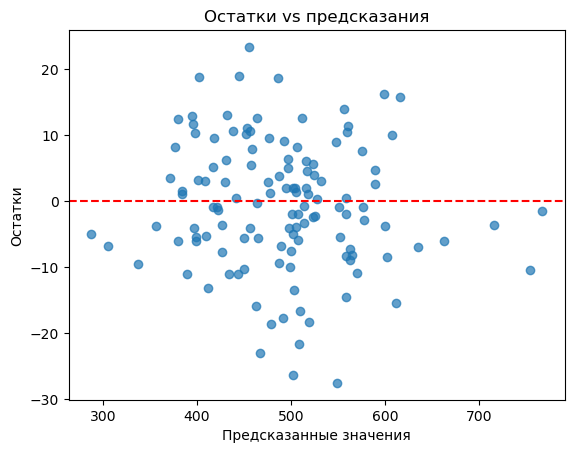

In [22]:
residuals = y_test - y_pred_test

plt.scatter(y_pred_test, residuals, alpha=0.7)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Предсказанные значения')
plt.ylabel('Остатки')
plt.title('Остатки vs предсказания')

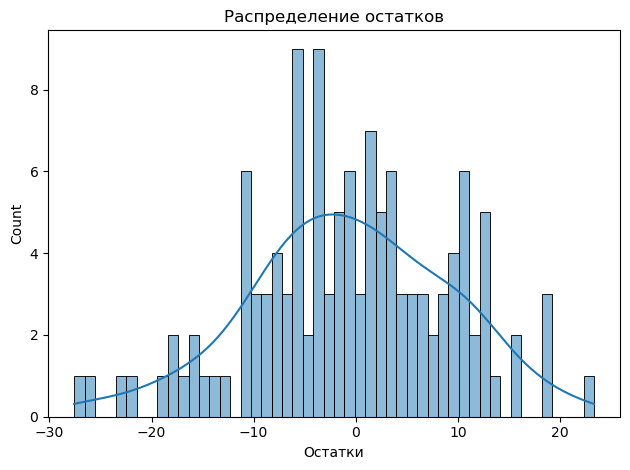

In [23]:
sns.histplot(residuals, bins=50, kde=True)
plt.xlabel('Остатки')
plt.title('Распределение остатков')
plt.tight_layout()
plt.show()